# Heart Disease Prediction Using Random Forest

**Machine Learning Project**

* Algorithm: Random Forest Classifier
* Problem Type: Classification
* Dataset: Heart Failure Prediction Dataset
* Dataset Size: 918 Records


## 1. Introduction

Heart disease is one of the major health concerns worldwide. Machine learning can help analyse health-related data and identify patterns.

In this project, we use the Random Forest Classification algorithm to predict heart disease using the Heart Failure Prediction Dataset.

**Dataset Name:** Heart Failure Prediction Dataset

**Dataset Source (Kaggle):**
https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction

**Dataset Size:** 918 rows and 12 columns



## 2. Objective

* To understand and analyse the heart disease dataset.
* To perform data preprocessing.
* To build a Random Forest classification model.
* To evaluate the model using different performance metrics.
* To identify important features influencing model predictions.


In [51]:
#Importing Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/heart.csv")

In [3]:
# Display first 5 rows
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
# Display last 5 rows
df.tail()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1
917,38,M,NAP,138,175,0,Normal,173,N,0.0,Up,0


In [5]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [6]:
# Statistical description
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


In [7]:
# Check missing values in each column
df.isnull().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [8]:
# Count duplicate rows
df.duplicated().sum()

np.int64(0)

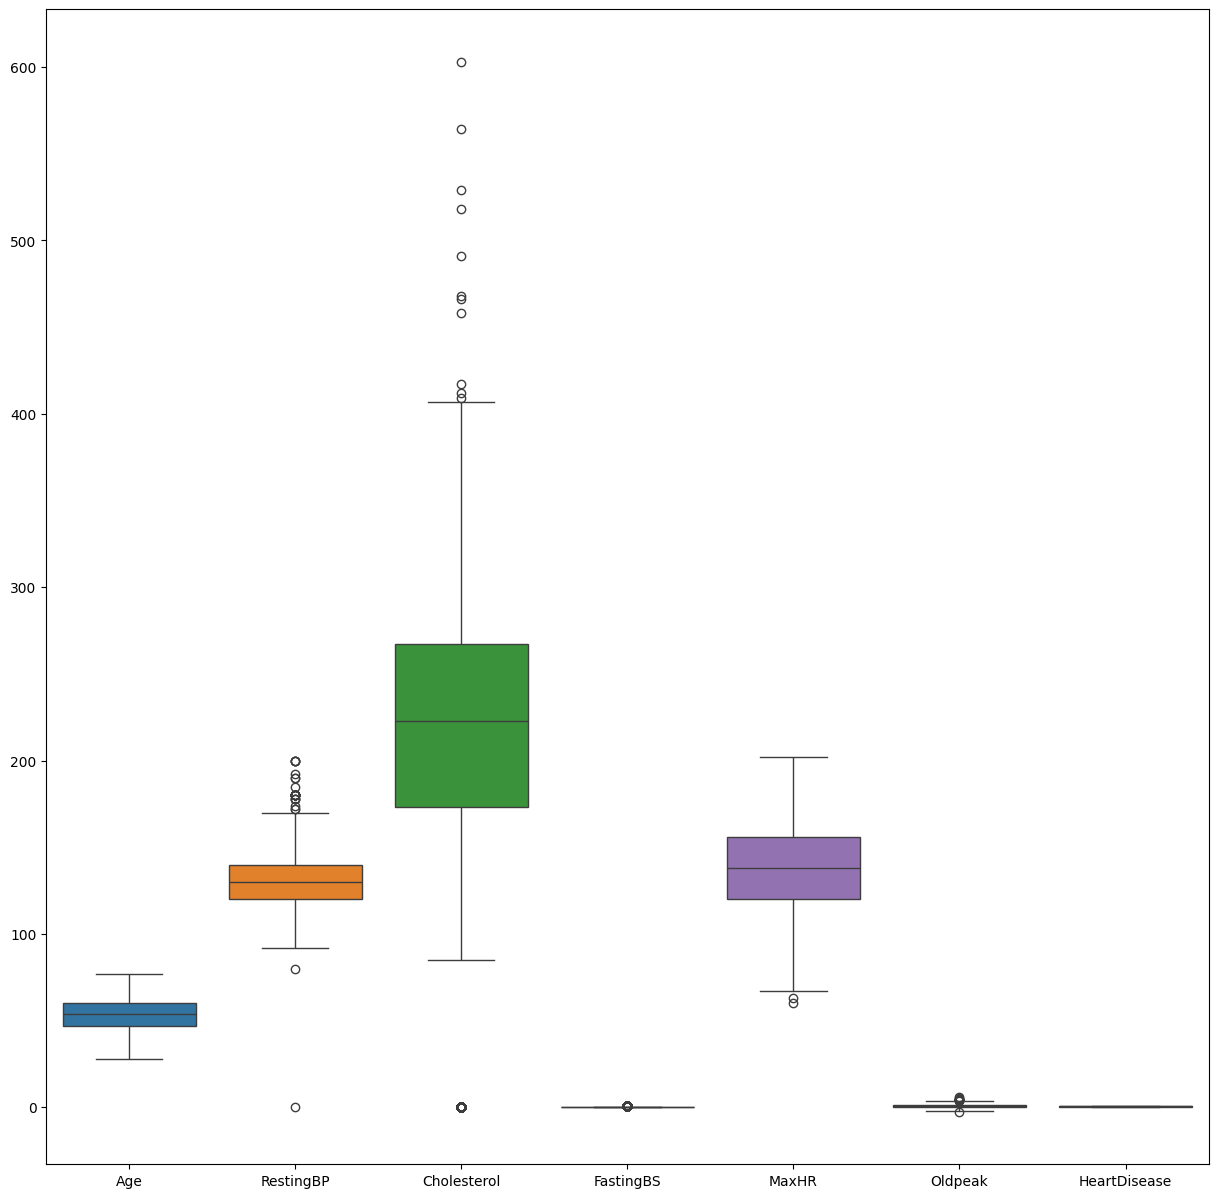

In [9]:
# Boxplots to detect outliers

plt.figure(figsize=(15,15))

sns.boxplot(data=df.select_dtypes(include='number'))

plt.show()

In [10]:
# Check zero values in numerical columns

(df.select_dtypes(include='number') == 0).sum()

,0
Age,0
RestingBP,1
Cholesterol,172
FastingBS,704
MaxHR,0
Oldpeak,368
HeartDisease,410


In [11]:
# Check minimum and maximum values

df.describe().T[['min', 'max']]

,min,max
Age,28.0,77.0
RestingBP,0.0,200.0
Cholesterol,0.0,603.0
FastingBS,0.0,1.0
MaxHR,60.0,202.0
Oldpeak,-2.6,6.2
HeartDisease,0.0,1.0


In [12]:
# Check records where RestingBP is zero

df[df['RestingBP'] == 0]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
449,55,M,NAP,0,0,0,Normal,155,N,1.5,Flat,1


In [13]:
# Check records where Cholesterol is zero

df[df['Cholesterol'] == 0]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
293,65,M,ASY,115,0,0,Normal,93,Y,0.0,Flat,1
294,32,M,TA,95,0,1,Normal,127,N,0.7,Up,1
295,61,M,ASY,105,0,1,Normal,110,Y,1.5,Up,1
296,50,M,ASY,145,0,1,Normal,139,Y,0.7,Flat,1
297,57,M,ASY,110,0,1,ST,131,Y,1.4,Up,1
...,...,...,...,...,...,...,...,...,...,...,...,...
514,43,M,ASY,122,0,0,Normal,120,N,0.5,Up,1
515,63,M,NAP,130,0,1,ST,160,N,3.0,Flat,0
518,48,M,NAP,102,0,1,ST,110,Y,1.0,Down,1
535,56,M,ASY,130,0,0,LVH,122,Y,1.0,Flat,1


In [14]:
# Calculate median cholesterol excluding zero values

df[df['Cholesterol'] != 0]['Cholesterol'].median()

237.0

In [15]:
# Replace zero values with median

df['Cholesterol'] = df['Cholesterol'].replace(0, 237)

In [16]:
# Replace zero values in RestingBP

df['RestingBP'] = df['RestingBP'].replace(0, df['RestingBP'].median())

In [17]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.538126,243.204793,0.233115,136.809368,0.887364,0.553377
std,9.432617,17.990127,53.401297,0.423046,25.460334,1.066570,0.497414
min,28.000000,80.000000,85.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,214.000000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,237.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


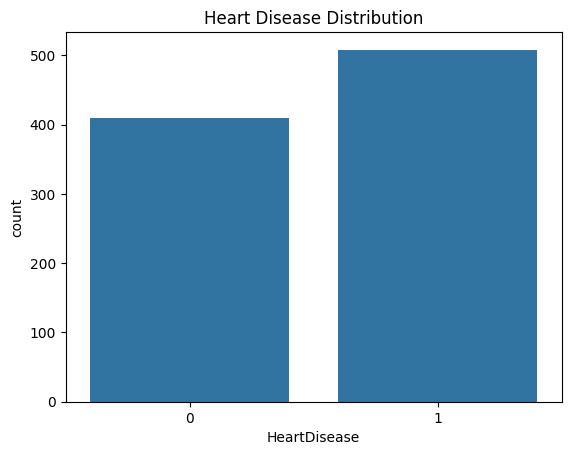

In [18]:
# Countplot of HeartDisease

sns.countplot(x='HeartDisease', data=df)

plt.title('Heart Disease Distribution')
plt.show()

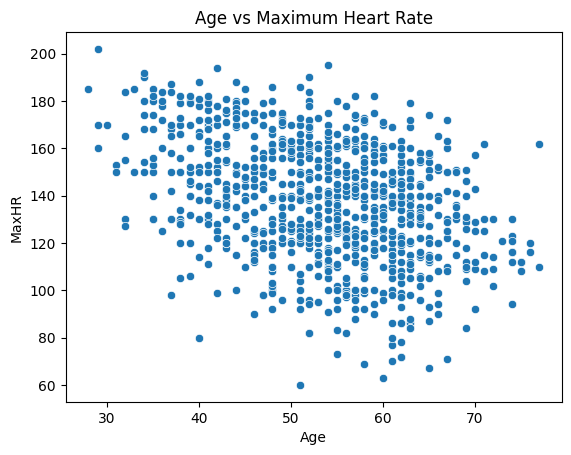

In [19]:
# Scatterplot

sns.scatterplot(x='Age', y='MaxHR', data=df)

plt.title('Age vs Maximum Heart Rate')
plt.show()

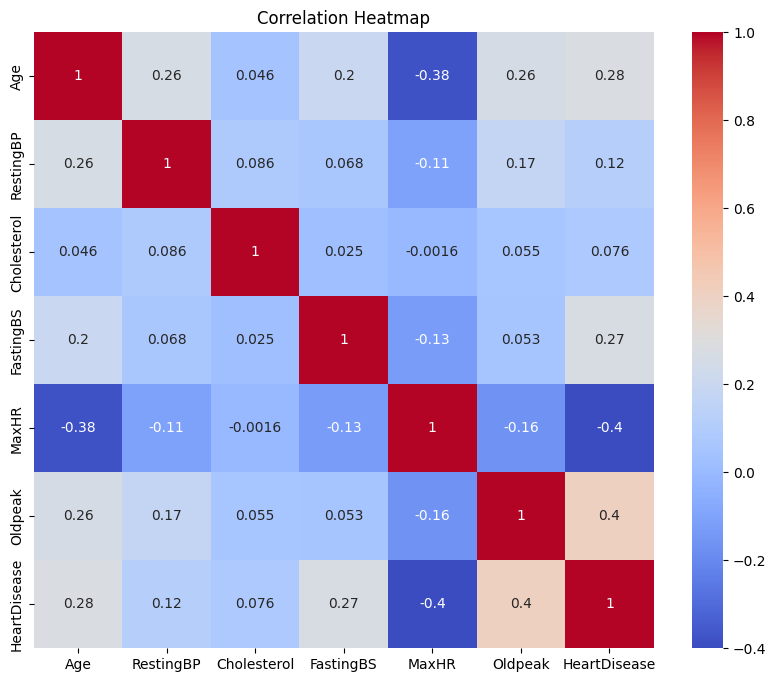

In [20]:
# Correlation heatmap

plt.figure(figsize=(10, 8))

sns.heatmap(df.select_dtypes(include='number').corr(),
            annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')
plt.show()

In [21]:
# Check categorical columns

df.select_dtypes(include='object').columns

Index(['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'], dtype='object')

In [22]:
# Check unique values in categorical columns

for column in df.select_dtypes(include='object').columns:
    print(column)
    print(df[column].value_counts())
    print()

Sex
Sex
M    725
F    193
Name: count, dtype: int64

ChestPainType
ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64

RestingECG
RestingECG
Normal    552
LVH       188
ST        178
Name: count, dtype: int64

ExerciseAngina
ExerciseAngina
N    547
Y    371
Name: count, dtype: int64

ST_Slope
ST_Slope
Flat    460
Up      395
Down     63
Name: count, dtype: int64



In [23]:
# Convert Sex into numerical values

df['Sex'] = df['Sex'].map({'M': 1, 'F': 0})

In [24]:
# Convert ExerciseAngina into numerical values

df['ExerciseAngina'] = df['ExerciseAngina'].map({'Y': 1, 'N': 0})

In [25]:
# Convert categorical columns into numerical values

df = pd.get_dummies(df, columns=['ChestPainType', 'RestingECG', 'ST_Slope'], dtype=int)

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                918 non-null    int64  
 1   Sex                918 non-null    int64  
 2   RestingBP          918 non-null    int64  
 3   Cholesterol        918 non-null    int64  
 4   FastingBS          918 non-null    int64  
 5   MaxHR              918 non-null    int64  
 6   ExerciseAngina     918 non-null    int64  
 7   Oldpeak            918 non-null    float64
 8   HeartDisease       918 non-null    int64  
 9   ChestPainType_ASY  918 non-null    int64  
 10  ChestPainType_ATA  918 non-null    int64  
 11  ChestPainType_NAP  918 non-null    int64  
 12  ChestPainType_TA   918 non-null    int64  
 13  RestingECG_LVH     918 non-null    int64  
 14  RestingECG_Normal  918 non-null    int64  
 15  RestingECG_ST      918 non-null    int64  
 16  ST_Slope_Down      918 non

In [27]:
# Separate input features

X = df.drop('HeartDisease', axis=1)

In [28]:
# Separate target variable

Y = df['HeartDisease']

In [29]:
print(X.head())
print(Y.head())

   Age  Sex  RestingBP  Cholesterol  FastingBS  MaxHR  ExerciseAngina  \
0   40    1        140          289          0    172               0   
1   49    0        160          180          0    156               0   
2   37    1        130          283          0     98               0   
3   48    0        138          214          0    108               1   
4   54    1        150          195          0    122               0   

   Oldpeak  ChestPainType_ASY  ChestPainType_ATA  ChestPainType_NAP  \
0      0.0                  0                  1                  0   
1      1.0                  0                  0                  1   
2      0.0                  0                  1                  0   
3      1.5                  1                  0                  0   
4      0.0                  0                  0                  1   

   ChestPainType_TA  RestingECG_LVH  RestingECG_Normal  RestingECG_ST  \
0                 0               0                  1       

In [30]:
from sklearn.model_selection import train_test_split

In [31]:
# Split the dataset

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

In [32]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Y_train:", Y_train.shape)
print("Y_test:", Y_test.shape)

X_train: (734, 18)
X_test: (184, 18)
Y_train: (734,)
Y_test: (184,)


In [33]:
from sklearn.ensemble import RandomForestClassifier

In [34]:
# Create Random Forest model

model = RandomForestClassifier()

In [35]:
# Train the model

model.fit(X_train, Y_train)

RandomForestClassifier()

In [36]:
# Predict the test data

Y_pred = model.predict(X_test)

print(Y_pred)

[0 1 1 1 0 1 1 0 1 1 1 0 1 0 1 1 0 1 1 0 1 1 0 1 1 1 0 1 0 0 1 0 0 1 1 0 1
 0 1 1 1 1 1 0 0 1 1 1 1 0 0 0 1 1 0 0 0 1 1 1 0 0 0 1 0 1 1 1 1 1 0 0 1 1
 0 1 0 1 0 1 1 1 1 0 1 1 0 1 0 0 0 1 1 0 0 0 1 0 1 1 0 1 1 0 1 1 0 0 1 0 1
 1 0 0 1 0 1 0 1 1 1 1 0 1 0 0 0 0 0 0 0 1 1 0 1 0 1 1 0 1 0 0 1 1 1 1 1 0
 0 0 0 1 1 0 1 0 0 0 0 1 0 0 1 0 1 1 0 1 0 0 1 1 0 1 0 1 0 1 0 1 1 1 0 1]


In [37]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(Y_test, Y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 0.8804347826086957
Accuracy Percentage: 88.04347826086956


In [38]:
result = pd.DataFrame({
    'Actual': Y_test,
    'Predicted': Y_pred
})

print(result)

     Actual  Predicted
668       0          0
30        1          1
377       1          1
535       1          1
807       0          0
..      ...        ...
211       1          1
745       1          1
584       1          1
878       0          0
451       1          1

[184 rows x 2 columns]


In [39]:
print("Training Accuracy:", model.score(X_train, Y_train))

print("Testing Accuracy:", model.score(X_test, Y_test))

Training Accuracy: 1.0
Testing Accuracy: 0.8804347826086957


[[69  8]
 [14 93]]


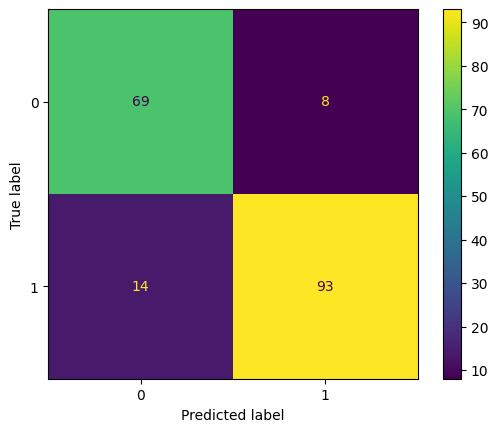

In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix

cm = confusion_matrix(Y_test, Y_pred)

print(cm)

# Display confusion matrix

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot()
plt.show()

In [41]:
from sklearn.metrics import classification_report

print(classification_report(Y_test, Y_pred))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86        77
           1       0.92      0.87      0.89       107

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184



In [42]:
from sklearn.model_selection import GridSearchCV

In [43]:
# Define parameters

param_grid = {
    'n_estimators': [100, 50, 150, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Create GridSearchCV

grid_search = GridSearchCV(
    RandomForestClassifier(),
    param_grid,
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train the model

grid_search.fit(X_train, Y_train)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 50, 150, 200]},
             verbose=1)

In [44]:
print("Best Parameters:", grid_search.best_params_)

print("Best Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 150}
Best Score: 0.8705432858074736


In [45]:
# Get the best model

best_model = grid_search.best_estimator_

In [46]:
# Predict using best model

Y_pred_best = best_model.predict(X_test)

In [47]:
# Calculate accuracy

best_accuracy = accuracy_score(Y_test, Y_pred_best)

print("Original Model Accuracy:", accuracy * 100)

print("Tuned Model Accuracy:", best_accuracy * 100)

Original Model Accuracy: 88.04347826086956
Tuned Model Accuracy: 86.95652173913044


In [48]:
print("Training Accuracy:", best_model.score(X_train, Y_train))

print("Testing Accuracy:", best_model.score(X_test, Y_test))

Training Accuracy: 0.9250681198910081
Testing Accuracy: 0.8695652173913043


In [49]:
# Feature importance

importance = best_model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

print(feature_importance)

              Feature  Importance
17        ST_Slope_Up    0.197337
16      ST_Slope_Flat    0.149223
7             Oldpeak    0.121004
8   ChestPainType_ASY    0.093006
6      ExerciseAngina    0.088435
5               MaxHR    0.077078
0                 Age    0.061191
3         Cholesterol    0.045824
2           RestingBP    0.037907
1                 Sex    0.034252
9   ChestPainType_ATA    0.033848
4           FastingBS    0.019226
10  ChestPainType_NAP    0.012273
12     RestingECG_LVH    0.008847
15      ST_Slope_Down    0.007770
13  RestingECG_Normal    0.004962
14      RestingECG_ST    0.004681
11   ChestPainType_TA    0.003136


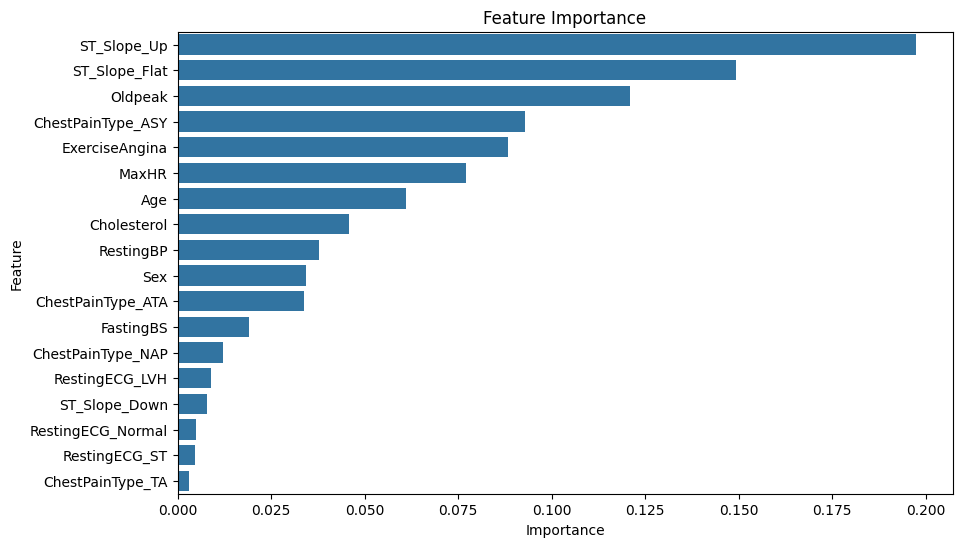

In [50]:
# Feature importance graph

plt.figure(figsize=(10, 6))

sns.barplot(x='Importance', y='Feature', data=feature_importance)

plt.title('Feature Importance')

plt.show()

## 16. Conclusion

In this project, a Random Forest Classifier was developed to predict heart disease using the Heart Failure Prediction Dataset.

The initial model achieved an accuracy of **88.04%** on the testing dataset. After hyperparameter tuning using GridSearchCV, the accuracy was **86.96%**.

Feature importance analysis showed that ST_Slope_Up, ExerciseAngina, ST_Slope_Flat and Oldpeak were among the most important features.

This project helped us understand data preprocessing, model training, evaluation and feature importance using the Random Forest algorithm.


